In [1]:
import torch

In [8]:
import requests
import zipfile
from pathlib import Path

data_path = Path("data/")
image_path = data_path / "pizza_stake_sushi"

if image_path.is_dir():
    print(f"directory {image_path} already exists")
else:
    print(f"did not find directory {image_path}, creating...")
    image_path.mkdir(parents = True , exist_ok = True)

with open(data_path / "pizza_stake_sushi.zip","wb") as f:
    request = requests.get("https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi.zip")
    print("Downloading pizza stake sushi data...")
    f.write(request.content)

with zipfile.ZipFile(data_path/"pizza_stake_sushi.zip","r") as zip_ref:
    print(f"Unzipping pizza, steak, suhsi data to {image_path}")
    zip_ref.extractall(image_path)

directory data\pizza_stake_sushi already exists
Unzipping pizza, steak, suhsi data to data\pizza_stake_sushi


In [9]:
import os
def walk_through_dir(dir_path):
    for dirpath, dirnames, filenames in os.walk(dir_path):
        print(f"There are {len(dirnames)} directories and {len(filenames)} images in '{dirpath}'.")

In [10]:
walk_through_dir(image_path)

There are 2 directories and 0 images in 'data\pizza_stake_sushi'.
There are 3 directories and 0 images in 'data\pizza_stake_sushi\test'.
There are 0 directories and 25 images in 'data\pizza_stake_sushi\test\pizza'.
There are 0 directories and 19 images in 'data\pizza_stake_sushi\test\steak'.
There are 0 directories and 31 images in 'data\pizza_stake_sushi\test\sushi'.
There are 3 directories and 0 images in 'data\pizza_stake_sushi\train'.
There are 0 directories and 78 images in 'data\pizza_stake_sushi\train\pizza'.
There are 0 directories and 75 images in 'data\pizza_stake_sushi\train\steak'.
There are 0 directories and 72 images in 'data\pizza_stake_sushi\train\sushi'.


In [11]:
train_dir = image_path/"train"
test_dir = image_path/"test"

train_dir , test_dir

(WindowsPath('data/pizza_stake_sushi/train'),
 WindowsPath('data/pizza_stake_sushi/test'))

[WindowsPath('data/pizza_stake_sushi/test/pizza/1152100.jpg'), WindowsPath('data/pizza_stake_sushi/test/pizza/1503858.jpg'), WindowsPath('data/pizza_stake_sushi/test/pizza/1687143.jpg')]
data\pizza_stake_sushi\train\pizza\3109486.jpg
pizza
random_image_path data\pizza_stake_sushi\train\pizza\3109486.jpg
image class: pizza
Image Height: 512
Image width: 512


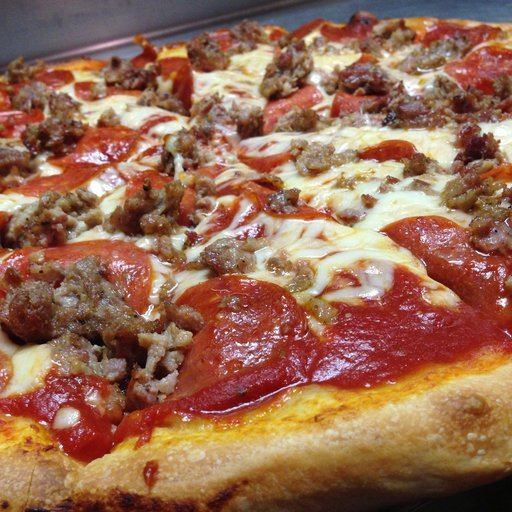

In [25]:
import random
from PIL import Image

image_path_list = list(image_path.glob("*/*/*.jpg"))
print(image_path_list[:3])

random_image_path = random.choice(image_path_list)
print(random_image_path)

image_class = random_image_path.parent.stem
print(image_class)

img = Image.open(random_image_path)

print(f"random_image_path {random_image_path}")
print(f"image class: {image_class}")
print(f"Image Height: {img.height}")
print(f"Image width: {img.width}")
img

(np.float64(-0.5), np.float64(511.5), np.float64(511.5), np.float64(-0.5))

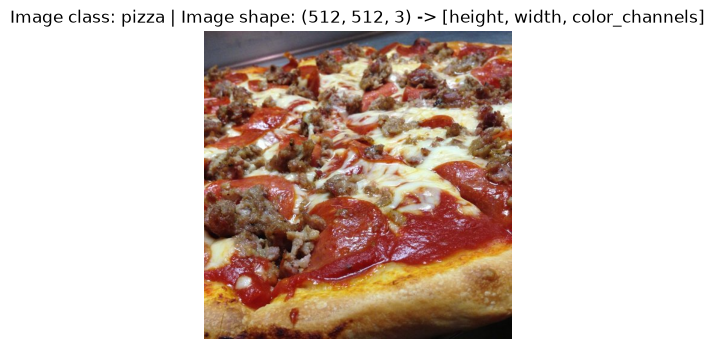

In [26]:
import numpy as np
import matplotlib.pyplot as plt

img_as_array = np.asarray(img)

plt.figure(figsize=(4,4))
plt.imshow(img_as_array)
plt.title(f"Image class: {image_class} | Image shape: {img_as_array.shape} -> [height, width, color_channels]")
plt.axis(False)

In [27]:
import torchvision
from torchvision import transforms, datasets
from torch.utils.data import DataLoader

data_transform = transforms.Compose([transforms.Resize(size = (64,64)) ,
                                    transforms.RandomHorizontalFlip(0.5),
                                    transforms.ToTensor()])

random.sample(image_path_list , k=3)

[WindowsPath('data/pizza_stake_sushi/train/pizza/2785084.jpg'),
 WindowsPath('data/pizza_stake_sushi/test/sushi/719108.jpg'),
 WindowsPath('data/pizza_stake_sushi/test/sushi/1987407.jpg')]

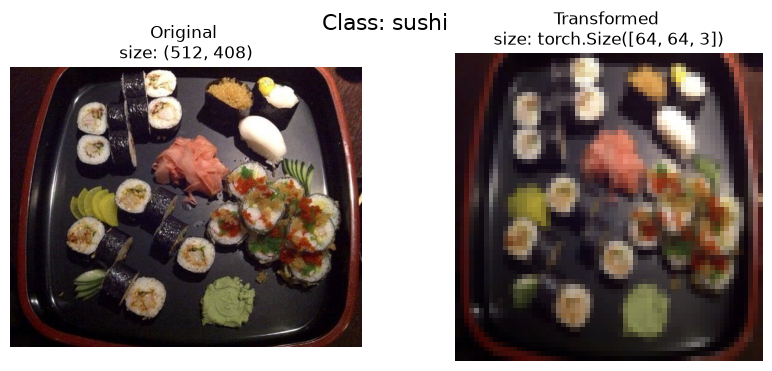

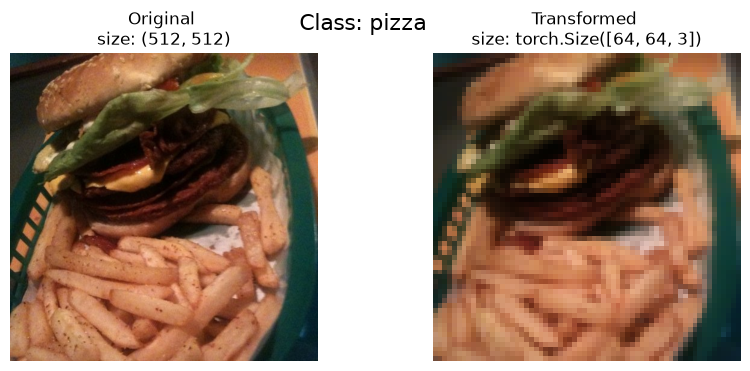

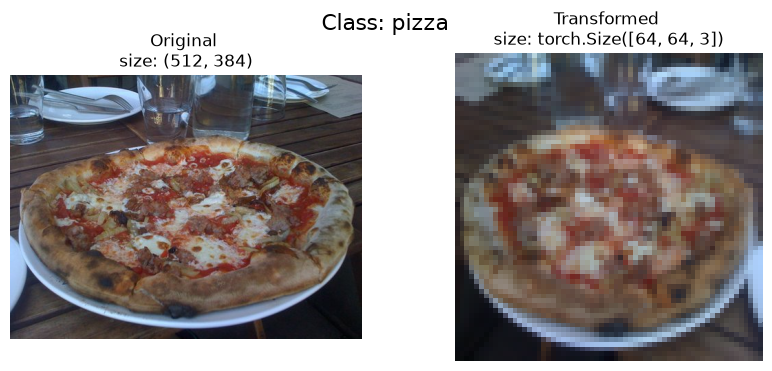

In [30]:
def plot_transformed_images(image_paths , transform, n=3, seed=42):
    random.seed(seed)
    random_image_paths = random.sample(image_paths , k=n)
    for image_path in random_image_paths:
        with Image.open(image_path) as f:
            fig , ax = plt.subplots(1, 2, figsize=(10, 4))
            ax[0].imshow(f)
            ax[0].set_title(f"Original \nsize: {f.size}")
            ax[0].axis(False)

            transformed_image = transform(f).permute(1,2,0)
            ax[1].imshow(transformed_image)
            ax[1].set_title(f"Transformed \nsize: {transformed_image.shape}")
            ax[1].axis(False)

            fig.suptitle(f"Class: {image_path.parent.stem}", fontsize=16)

plot_transformed_images(image_path_list,
                        transform=data_transform,
                        n=3)
    

In [35]:
from torchvision import datasets

train_data = datasets.ImageFolder(root = train_dir, transform = data_transform , target_transform = None)
test_data = datasets.ImageFolder(root = test_dir, transform = data_transform , target_transform = None)

train_data , test_data

(Dataset ImageFolder
     Number of datapoints: 225
     Root location: data\pizza_stake_sushi\train
     StandardTransform
 Transform: Compose(
                Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
                RandomHorizontalFlip(p=0.5)
                ToTensor()
            ),
 Dataset ImageFolder
     Number of datapoints: 75
     Root location: data\pizza_stake_sushi\test
     StandardTransform
 Transform: Compose(
                Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
                RandomHorizontalFlip(p=0.5)
                ToTensor()
            ))

In [36]:
len(train_data) , len(test_data)

(225, 75)

In [32]:
class_names = train_data.classes
class_names

['pizza', 'steak', 'sushi']

In [33]:
class_dict = train_data.class_to_idx
class_dict

{'pizza': 0, 'steak': 1, 'sushi': 2}

In [38]:
from torch.utils.data import DataLoader
BATCH_SIZE = 1

train_dataloader = DataLoader(dataset=train_data, batch_size=BATCH_SIZE, num_workers=os.cpu_count(), shuffle=True)
test_dataloader = DataLoader(dataset = test_data, batch_size = BATCH_SIZE, num_workers = os.cpu_count(), shuffle = False)

train_dataloader, test_dataloader

(<torch.utils.data.dataloader.DataLoader at 0x2a056f82a80>,
 <torch.utils.data.dataloader.DataLoader at 0x2a05d013890>)

In [40]:
len(train_dataloader), len(test_dataloader)

(225, 75)

In [41]:
img , label = next(iter(train_dataloader))
print(f"Image shape is {img.shape}")
print(f"Label shape is {label.shape}")

Image shape is torch.Size([1, 3, 64, 64])
Label shape is torch.Size([1])


In [50]:
import torch
from torch import nn

class TinyVGG(nn.Module):
    def __init__(self, input_shape, hidden_units, output_shape):
        super().__init__()
        self.conv_block_1 = nn.Sequential(
            nn.Conv2d(
            in_channels = input_shape,
            out_channels = hidden_units,
            kernel_size = 3,
            stride =1, 
            padding = 1
        ), nn.ReLU(),
            nn.Conv2d(
            in_channels = hidden_units,
            out_channels = hidden_units,
            kernel_size = 3,
            stride =1, 
            padding = 1
        ), nn.ReLU(),
        nn.MaxPool2d(kernel_size = 2)
        )

        self.conv_block_2 = nn.Sequential(
                    nn.Conv2d(
                    in_channels = hidden_units,
                    out_channels = hidden_units,
                    kernel_size = 3,
                    stride =1, 
                    padding = 1
                ), nn.ReLU(),
                    nn.Conv2d(
                    in_channels = hidden_units,
                    out_channels = hidden_units,
                    kernel_size = 3,
                    stride =1, 
                    padding = 1
                ), nn.ReLU(),
                nn.MaxPool2d(kernel_size = 2)
                )

        self.classifier = nn.Sequential(
            nn.Flatten(), 
            nn.Linear(in_features = hidden_units* 16 * 16 , out_features = output_shape)
        )

    def forward(self , x):
        x = self.conv_block_1(x)
        x = self.conv_block_2(x)
        x = self.classifier(x)
        return x

In [51]:
model_0 = TinyVGG(input_shape = 3, hidden_units = 10, output_shape = len(class_names)).to("cpu")
model_0

TinyVGG(
  (conv_block_1): Sequential(
    (0): Conv2d(3, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block_2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2560, out_features=3, bias=True)
  )
)

In [47]:
len(class_names)

3

In [68]:
def train_step(model: torch.nn.Module,
               dataloader: torch.utils.data.DataLoader,
               loss_fn: torch.nn.Module,
               optimizer: torch.optim.Optimizer):
    model.train()

    train_loss , train_acc = 0,0
    for batch , (X,y) in enumerate(dataloader):
        X,y = X.to("cpu"), y.to("cpu")

        y_pred = model(X)

        loss = loss_fn(y_pred , y)
        train_loss += loss.item()

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        y_pred_labels = y_pred.argmax(dim=1)
        train_acc += ((y_pred_labels == y).sum().item()) / len(y_pred)

    train_loss = train_loss / len(dataloader)
    train_acc = train_acc / len(dataloader)
    return train_loss, train_acc 

In [72]:
def test_step(model: torch.nn.Module,
               dataloader: torch.utils.data.DataLoader,
               loss_fn: torch.nn.Module):
    model.eval()

    test_loss , test_acc = 0,0

    with torch.inference_mode():
        for batch , (X,y) in enumerate(dataloader):
            X,y = X.to("cpu"), y.to("cpu")

            test_pred_logits = model(X)

            loss = loss_fn(test_pred_logits , y)
            test_loss += loss.item()

            y_pred_labels = test_pred_logits.argmax(dim=1)
            test_acc += ((y_pred_labels == y).sum().item()) / len(test_pred_logits)

    test_loss = test_loss / len(dataloader)
    test_acc = test_acc / len(dataloader)
    return test_loss, test_acc 

In [73]:
from tqdm.auto import tqdm

def train(model: torch.nn.Module,
          train_dataloader: torch.utils.data.DataLoader,
          test_dataloader: torch.utils.data.DataLoader,
          optimizer: torch.optim.Optimizer,
          loss_fn: torch.nn.Module = nn.CrossEntropyLoss(),
          epochs: int=5):

    results = {"train_loss": [],
               "train_acc": [],
               "test_loss": [],
               "test_acc": []}

    for epoch in tqdm(range(epochs)):
        train_loss , train_acc = train_step(model = model,
                                            dataloader = train_dataloader,
                                            loss_fn = loss_fn,
                                            optimizer = optimizer)
        test_loss , test_acc = test_step(model = model,
                                        dataloader = test_dataloader,
                                        loss_fn = loss_fn)

        print(f"Epoch: {epoch+1} | "
            f"train_loss: {train_loss:.4f} | "
            f"train_acc: {train_acc:.4f} | "
            f"test_loss: {test_loss:.4f} | "
            f"test_acc: {test_acc:.4f}"
        )

        results['train_loss'].append(train_loss)
        results['train_acc'].append(train_acc)
        results['test_loss'].append(test_loss)
        results['test_acc'].append(test_acc)

    return results

In [74]:
torch.manual_seed(42)
model_0 = TinyVGG(input_shape = 3, hidden_units = 10, output_shape = len(class_names)).to("cpu")

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_0.parameters() , lr = 0.001)

model_0_results = train(
    model=model_0,
    train_dataloader=train_dataloader,
    test_dataloader=test_dataloader,
    optimizer=optimizer,
    loss_fn=loss_fn,
    epochs=5
)

 20%|██        | 1/5 [03:48<15:14, 228.54s/it]

Epoch: 1 | train_loss: 1.1181 | train_acc: 0.2978 | test_loss: 1.0964 | test_acc: 0.3333


 40%|████      | 2/5 [07:08<10:34, 211.61s/it]

Epoch: 2 | train_loss: 1.1008 | train_acc: 0.3289 | test_loss: 1.0997 | test_acc: 0.2533


 60%|██████    | 3/5 [09:58<06:25, 192.89s/it]

Epoch: 3 | train_loss: 1.1004 | train_acc: 0.3200 | test_loss: 1.0994 | test_acc: 0.3333


 80%|████████  | 4/5 [12:11<02:49, 169.22s/it]

Epoch: 4 | train_loss: 1.0989 | train_acc: 0.3200 | test_loss: 1.0996 | test_acc: 0.3333


100%|██████████| 5/5 [14:26<00:00, 173.33s/it]

Epoch: 5 | train_loss: 1.0988 | train_acc: 0.3244 | test_loss: 1.1002 | test_acc: 0.3333


In [ ]:
torch.manual_seed(42)
model_1 = TinyVGG(input_shape = 3, hidden_units = 10, output_shape = len(class_names)).to("cpu")

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_1.parameters() , lr = 0.001)

model_1_results = train(
    model=model_1,
    train_dataloader=train_dataloader,
    test_dataloader=test_dataloader,
    optimizer=optimizer,
    epochs = 20)

In [ ]:
torch.manual_seed(42)
model_2 = TinyVGG(input_shape = 3, hidden_units = 10, output_shape = len(class_names)).to("cpu")

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_2.parameters() , lr = 0.001)

model_2_results = train(
    model=model_2,
    train_dataloader=train_dataloader,
    test_dataloader=test_dataloader,
    optimizer=optimizer,
    epochs = 50)

In [ ]:
torch.manual_seed(42)
model_3 = TinyVGG(input_shape = 3, hidden_units = 20, output_shape = len(class_names)).to("cpu")

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_3.parameters() , lr = 0.001)

model_3_results = train(
    model=model_3,
    train_dataloader=train_dataloader,
    test_dataloader=test_dataloader,
    optimizer=optimizer,
    epochs = 20)

In [75]:
import requests
from pathlib import Path
import zipfile

data_path = Path("data/")
image_path = data_path / "pizza_stake_sushi_20_percent"

if image_path.is_dir():
    print(f"{image_path} already exists")
else:
    print(f"Did not find {image_path} directory, creating one...") 
    image_path.mkdir(parents = True , exist_ok = True)

with open(data_path / "pizza_stake_sushi_20_percent.zip" , "wb") as f:
    request = requests.get("https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi_20_percent.zip")
    print("Downloading pizza, steak, sushi 20% data...")
    f.write(request.content)

with zipfile.ZipFile(data_path / "pizza_stake_sushi_20_percent.zip" , "r") as zip_ref: 
    print("Unzipping pizza, steak, sushi 20% data...") 
    zip_ref.extractall(image_path)

Did not find data\pizza_stake_sushi_20_percent directory, creating one...
Unzipping pizza, steak, sushi 20% data...


In [76]:
walk_through_dir(image_path)

There are 2 directories and 0 images in 'data\pizza_stake_sushi_20_percent'.
There are 3 directories and 0 images in 'data\pizza_stake_sushi_20_percent\test'.
There are 0 directories and 46 images in 'data\pizza_stake_sushi_20_percent\test\pizza'.
There are 0 directories and 58 images in 'data\pizza_stake_sushi_20_percent\test\steak'.
There are 0 directories and 46 images in 'data\pizza_stake_sushi_20_percent\test\sushi'.
There are 3 directories and 0 images in 'data\pizza_stake_sushi_20_percent\train'.
There are 0 directories and 154 images in 'data\pizza_stake_sushi_20_percent\train\pizza'.
There are 0 directories and 146 images in 'data\pizza_stake_sushi_20_percent\train\steak'.
There are 0 directories and 150 images in 'data\pizza_stake_sushi_20_percent\train\sushi'.


In [77]:
train_data_20_path = image_path / "train"
test_data_20_path = image_path / "test"

train_data_20_path , test_data_20_path

(WindowsPath('data/pizza_stake_sushi_20_percent/train'),
 WindowsPath('data/pizza_stake_sushi_20_percent/test'))

In [78]:
from torchvision.datasets import ImageFolder
from torchvision import transforms
from torch.utils.data import DataLoader

simple_transform = transforms.Compose(
    [transforms.Resize(size = (64,64)),
    transforms.ToTensor()]
)

train_data_20 = datasets.ImageFolder(train_data_20_path , transform = simple_transform)
test_data_20 = datasets.ImageFolder(test_data_20_path , transform = simple_transform)

train_dataloader_20 = DataLoader(train_data_20 , batch_size = 32, num_workers = os.cpu_count(), shuffle = True)
test_dataloader_20 = DataLoader(test_data_20 , batch_size = 32, num_workers = os.cpu_count(), shuffle = False)

In [79]:
torch.manual_seed(42)
model_4 = TinyVGG(input_shape = 3, hidden_units = 20, output_shape = len(class_names)).to("cpu")

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_4.parameters() , lr = 0.001)

model_4_results = train(
    model=model_4,
    train_dataloader=train_dataloader_20,
    test_dataloader=test_dataloader_20,
    optimizer=optimizer,
    epochs = 20)

  5%|▌         | 1/20 [03:46<1:11:48, 226.74s/it]

Epoch: 1 | train_loss: 1.1042 | train_acc: 0.3312 | test_loss: 1.1004 | test_acc: 0.2875


  5%|▌         | 1/20 [06:21<2:00:46, 381.37s/it]


KeyboardInterrupt: 

In [81]:
custom_image = "pizza_dad.jpeg"
with open("pizza_dad.jpeg" , "wb") as f:
    request = requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/04-pizza-dad.jpeg")
    f.write(request.content)

In [82]:
import torchvision
img = torchvision.io.read_image(custom_image)
img

tensor([[[154, 173, 181,  ...,  21,  18,  14],
         [146, 165, 181,  ...,  21,  18,  15],
         [124, 146, 172,  ...,  18,  17,  15],
         ...,
         [ 72,  59,  45,  ..., 152, 150, 148],
         [ 64,  55,  41,  ..., 150, 147, 144],
         [ 64,  60,  46,  ..., 149, 146, 143]],

        [[171, 190, 193,  ...,  22,  19,  15],
         [163, 182, 193,  ...,  22,  19,  16],
         [141, 163, 184,  ...,  19,  18,  16],
         ...,
         [ 55,  42,  28,  ..., 107, 104, 103],
         [ 47,  38,  24,  ..., 108, 104, 102],
         [ 47,  43,  29,  ..., 107, 104, 101]],

        [[119, 138, 147,  ...,  17,  14,  10],
         [111, 130, 145,  ...,  17,  14,  11],
         [ 87, 111, 136,  ...,  14,  13,  11],
         ...,
         [ 35,  22,   8,  ...,  52,  52,  48],
         [ 27,  18,   4,  ...,  50,  49,  44],
         [ 27,  23,   9,  ...,  49,  46,  43]]], dtype=torch.uint8)

(np.float64(-0.5), np.float64(3023.5), np.float64(4031.5), np.float64(-0.5))

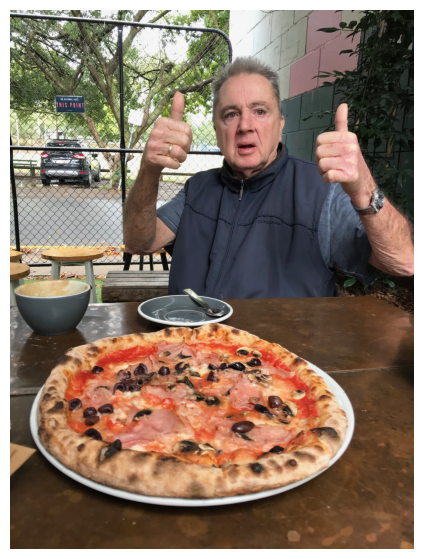

In [83]:
plt.figure(figsize = (10,7))
plt.imshow(img.permute(1,2,0))
plt.axis(False)

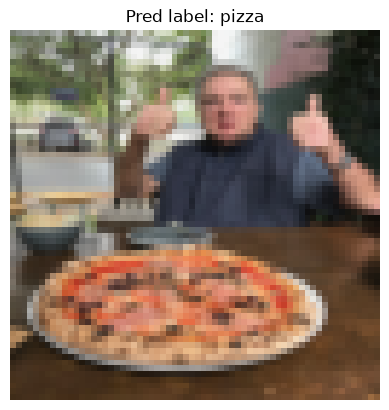

In [84]:
model_4.eval()
with torch.inference_mode():
    img = img/255

    resize = transforms.Resize(size = (64,64))
    img = resize(img)

    batch = img.unsqueeze(0).to("cpu")

    y_pred_logit = model_4(batch)
    y_pred_labels = y_pred_logit.argmax(dim=1)

plt.imshow(img.permute(1,2,0))
plt.title(f"Pred label: {class_names[y_pred_labels]}")
plt.axis(False);